# 03 Word2Vec embeddings trained on Lingala news

**Question:** can dense word embeddings learned from only 608 articles (about 110k tokens) replace sparse TF-IDF features?

Word2Vec (Mikolov et al., 2013) learns a vector for each word by predicting its neighbours (skip-gram) or predicting a
word from its neighbours (CBOW). Words used in similar contexts get similar vectors. Here we

1. train Word2Vec on the **training articles only** (no validation/test text, so no leakage),
2. inspect the nearest neighbours to see whether the vectors make sense,
3. represent each article as the **average of its word vectors** and train logistic regression on that,
4. save the best vectors to initialise the BiLSTM / BiGRU in notebook 04.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Change this to your own GitHub repository before running in Colab
REPO_URL = "https://github.com/YOUR-GITHUB-USERNAME/lingala-news-classification.git"

if IN_COLAB and not Path("lingala-news-classification").exists():
    !git clone -q {REPO_URL}
if IN_COLAB:
    %cd lingala-news-classification
    %pip install -q -r requirements.txt

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /home/claude/lingala-news-classification


In [2]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

from src import config, data_loading, evaluation, plots
from src.experiment_log import log_experiment
from src.reproducibility import set_seed
from src.word_embeddings import average_document_vectors, nearest_words, train_word2vec

MODEL_FAMILY = "word2vec"
set_seed(config.RANDOM_SEED)

train, validation, test = data_loading.load_all_splits()
train_ids = data_loading.labels_to_ids(train["category"])
validation_ids = data_loading.labels_to_ids(validation["category"])
test_ids = data_loading.labels_to_ids(test["category"])

In [3]:
def classifier():
    return LogisticRegression(C=10, class_weight="balanced", max_iter=5000, random_state=config.RANDOM_SEED)

experiments = {
    "W1_skipgram_100d": {"skip_gram": True, "dimensions": 100, "window": 5, "min_count": 2},
    "W2_cbow_100d": {"skip_gram": False, "dimensions": 100, "window": 5, "min_count": 2},
    "W3_skipgram_300d": {"skip_gram": True, "dimensions": 300, "window": 5, "min_count": 2},
    "W4_skipgram_window10": {"skip_gram": True, "dimensions": 100, "window": 10, "min_count": 2},
    "W5_skipgram_strip_accents": {"skip_gram": True, "dimensions": 100, "window": 5, "min_count": 2, "strip_accents": True},
}

rows, models = [], {}
for name, settings in experiments.items():
    word2vec = train_word2vec(train[config.TEXT_COLUMN], settings)
    accents = settings.get("strip_accents", False)
    x_train = average_document_vectors(train[config.TEXT_COLUMN], word2vec, accents)
    x_validation = average_document_vectors(validation[config.TEXT_COLUMN], word2vec, accents)
    model = classifier().fit(x_train, train_ids)
    scores = evaluation.compute_scores(validation_ids, model.predict_proba(x_validation))
    log_experiment(MODEL_FAMILY, name, "validation", settings, scores, "Averaged Word2Vec + logistic regression")
    rows.append({"experiment": name, "vocabulary": len(word2vec.wv), **{k: scores[k] for k in ["macro_f1", "weighted_f1", "accuracy"]}})
    models[name] = (word2vec, model, settings)

pd.DataFrame(rows).sort_values("macro_f1", ascending=False)

Logged 'W1_skipgram_100d' (validation) to word2vec.csv


Logged 'W2_cbow_100d' (validation) to word2vec.csv


Logged 'W3_skipgram_300d' (validation) to word2vec.csv


Logged 'W4_skipgram_window10' (validation) to word2vec.csv


Logged 'W5_skipgram_strip_accents' (validation) to word2vec.csv


,experiment,vocabulary,macro_f1,weighted_f1,accuracy
4,W5_skipgram_strip_accents,4790,0.8658,0.9013,0.8966
2,W3_skipgram_300d,4831,0.8501,0.8915,0.8851
0,W1_skipgram_100d,4831,0.8392,0.8854,0.8736
1,W2_cbow_100d,4831,0.8094,0.8362,0.8276
3,W4_skipgram_window10,4831,0.8093,0.8567,0.8506


## Do the vectors make sense? Nearest neighbours

In [4]:
word2vec = models["W1_skipgram_100d"][0]
probe_words = ["ebola", "coronavirus", "léopards", "match", "budget", "banque", "tshisekedi", "mokonzi", "bokono", "mbongo"]
for word, neighbours in nearest_words(word2vec, probe_words).items():
    print(f"{word:12s} -> {', '.join(neighbours)}")

ebola        -> virus, biena, bokono, komonisama, biyibami, mangina
coronavirus  -> yuhan, corovirus, bopanzani, haskell, mobeli, epanzani
léopards     -> balongwe, ecureils, cuper, séniors, seleccion, alongolami
match        -> aller, retour, jss, libungu, zesco, tulu
budget       -> plan, ekanisi, mipesama, ii, loisirs, eleko
banque       -> centrale, privée, bcc, bgif, libulu, comptes
tshisekedi   -> félix, président, tshikedi, felix, belgrade, tshiskedi
mokonzi      -> avanda, moboti, télé, pré, moknzi, mboka
bokono       -> virus, mobeli, bomonani, bosili, azuwami, komonisama
mbongo       -> biyike, mizwi, bozito, ekiti, misosolo, ozwi


**Reading the neighbours.** Frequent topic words get sensible neighbours: *ebola* → *virus*, *bokono* 'disease', *Mangina*
(the town where the 2018 outbreak started); *banque* → *centrale*, *BCC* (Banque Centrale du Congo); *match* → *aller*, *retour*.
The vectors also pull **spelling variants** together: *tshisekedi* → *tshikedi*, *tshiskedi*; *coronavirus* → *corovirus*;
*mokonzi* 'leader' → *moknzi*. This is useful: a bag-of-words model treats each misspelling as an unrelated word.
Rarer words get noisy neighbours (*léopards* → *ecureils*, *seleccion*: other national teams, but also unrelated words), because with
about 110k tokens many words are seen only a handful of times; Word2Vec is normally trained on hundreds of millions of tokens.

## Final evaluation of the best averaged-embedding model on the test set

Logged 'FINAL_W5_skipgram_strip_accents' (test) to word2vec.csv
Saved test probabilities to /home/claude/lingala-news-classification/results/predictions/word2vec_average.csv
W5_skipgram_strip_accents {'accuracy': 0.8743, 'macro_precision': 0.8695, 'macro_recall': 0.8654, 'macro_f1': 0.8598, 'weighted_f1': 0.8747, 'log_loss': 0.3688, 'f1_politics': 0.8976, 'f1_health': 0.8235, 'f1_sports': 1.0, 'f1_business': 0.7179, 'macro_f1_ci_low': 0.7969, 'macro_f1_ci_high': 0.9093}
              precision    recall  f1-score   support

    politics      0.876     0.920     0.898       100
      health      0.966     0.718     0.824        39
      sports      1.000     1.000     1.000        19
    business      0.636     0.824     0.718        17

    accuracy                          0.874       175
   macro avg      0.870     0.865     0.860       175
weighted avg      0.886     0.874     0.875       175



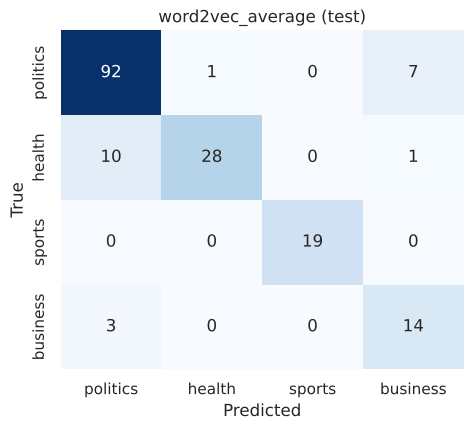

In [5]:
best_name = max(rows, key=lambda r: r["macro_f1"])["experiment"]
word2vec, model, settings = models[best_name]
accents = settings.get("strip_accents", False)
probabilities = model.predict_proba(average_document_vectors(test[config.TEXT_COLUMN], word2vec, accents))
scores = evaluation.compute_scores(test_ids, probabilities)
scores["macro_f1_ci_low"], scores["macro_f1_ci_high"] = evaluation.bootstrap_confidence_interval(test_ids, probabilities.argmax(1))
log_experiment(MODEL_FAMILY, f"FINAL_{best_name}", "test", settings, scores, "Final test evaluation")
evaluation.save_test_predictions(probabilities, "word2vec_average")
print(best_name, scores)
evaluation.print_classification_report(test_ids, probabilities)
plots.plot_confusion_matrix(test_ids, probabilities, "word2vec_average", "test");

**Result.** Averaged skip-gram vectors (with accents stripped) reach a test macro-F1 close to, and here slightly above, the TF-IDF + SVM
baseline from notebook 02 (compare the two in notebook 07). The validation scores pointed the other way, and the bootstrap intervals
overlap widely, so the honest conclusion is that the two are **comparable** on this test set, not that one is better.

Why can 100 dense numbers per article compete with tens of thousands of sparse TF-IDF features? The embeddings share information between
related words (misspellings, accent variants, words from the same news story), which matters most for the smallest class, **business**:
its recall is higher than with TF-IDF. What averaging loses is word order and the ability to weight one decisive word strongly.

We save the 100-d skip-gram vectors with accents kept (W1), because the RNN vocabulary in notebook 04 keeps accents, so the network
can start from these vectors and *fine-tune* them for the task instead of averaging them.

In [6]:
config.MODELS_DIRECTORY.mkdir(exist_ok=True)
models["W1_skipgram_100d"][0].save(str(config.MODELS_DIRECTORY / "word2vec_lingala_100d.model"))
print("Saved word2vec_lingala_100d.model")

Saved word2vec_lingala_100d.model
